# Hands-on P03: Evolusi 5 Arsitektur Neural Network (`MLP → CNN → ResNet → MobileNetV2 → EfficientNet`)

**Durasi Hands-on:** ±42 menit · **Gaya Kode (*Visual-First*):** Sel latihan Anda hanya **3–10 baris**, langsung memvisualisasikan hasilnya pada **Disney Frozen Figurine Dataset** (`data/frozen_v1/`).  
**Mode Aman Offline:** Semua arsitektur dimuat dengan `weights=None` agar cepat dan tidak bergantung unduhan besar (penggunaan bobot *pretrained ImageNet* / Transfer Learning akan menjadi fokus utama **P04**).

> **Cara Menjalankan:** Tekan `Shift + Enter` secara berurutan dari atas ke bawah. Isi sel bertanda `# TODO` lalu lihat Hint bila perlu.

## Setup 1/3: Memanggil Pustaka (*Libraries*) Python
Kita panggil alat-alat Python yang diperlukan dan mencetak versinya agar eksperimen dapat direproduksi (*reproducible*).

In [1]:
import os                           # Untuk membaca pengaturan komputer / environment
import random                       # Untuk mengunci angka acak bawaan Python
from pathlib import Path            # Untuk mengatur alamat folder & file

import numpy as np                  # NumPy: untuk mengolah matriks/tabel angka
import pandas as pd                 # Pandas: untuk membuat tabel laporan
import matplotlib.pyplot as plt     # Matplotlib: untuk menampilkan gambar & grafik
import tensorflow as tf             # TensorFlow/Keras: untuk membangun & melatih Neural Network
import time                         # Untuk mengukur kecepatan inferensi tiap arsitektur
from PIL import Image, ImageOps    # Untuk memuat foto & koreksi orientasi EXIF

print("✅ Semua library berhasil dimuat!")
print("Versi NumPy      :", np.__version__)
print("Versi TensorFlow :", tf.__version__)

✅ Semua library berhasil dimuat!
Versi NumPy      : 2.5.5
Versi TensorFlow : 2.21.0


## Setup 2/3: Deteksi Google Colab & Mengunci `SEED = 42`
Notebook ini bisa berjalan di **Google Colab** maupun di **komputer lokal**. Kita kunci `SEED = 42` agar hasil acak selalu konsisten setiap kali dijalankan ulang.

In [2]:
# Cek apakah notebook dijalankan di Google Colab atau lokal
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Kunci angka acak (SEED = 42) untuk reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Berjalan di Google Colab :", IN_COLAB)
print("SEED dikunci pada        :", SEED)

Berjalan di Google Colab : False
SEED dikunci pada        : 42


## Setup 3/3: Konfigurasi Proyek & Alamat Folder
Daftar kelas, ukuran gambar (`IMG_SIZE = 224`), dan folder data disimpan sebagai variabel konfigurasi di sini (tidak di-*hardcode*) agar nanti mudah diganti ke foto Disney buatan sendiri.

In [3]:
# Konfigurasi utama proyek (dinamis — tetap aman jika jumlah foto dataset ditambah nanti)
IMG_SIZE = 224
SMOKE_TEST = os.environ.get("SMOKE_TEST", "0") == "1"
CLASS_NAMES = ["anna", "elsa", "kristoff", "olaf", "sven"]


# Cari folder utama proyek yang memiliki folder "data/"
BASE_DIR = Path(".")
for folder in [Path("."), Path(".."), Path("../.."), Path("../../..")]:
    if (folder / "data").exists():
        BASE_DIR = folder
        break

# Gunakan dataset proyek utama Disney Frozen (otomatis fallback ke data/sample jika belum tersedia)
DATA_DIR = BASE_DIR / "data" / "frozen_v1"
if not DATA_DIR.exists():
    DATA_DIR = BASE_DIR / "data" / "sample"
RESULTS_DIR = BASE_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Mode SMOKE_TEST  :", SMOKE_TEST)
print("Folder Dataset   :", DATA_DIR.resolve())
print("Folder Hasil     :", RESULTS_DIR.resolve())

Mode SMOKE_TEST  : False
Folder Dataset   : D:\Haerul\HaloTech-Private-DeepLearning\data\frozen_v1
Folder Hasil     : D:\Haerul\HaloTech-Private-DeepLearning\results


## Tahap 0.2: Aktifkan Alat Visualisasi Siap Pakai
Jalankan sel di bawah **satu kali saja** (`Shift + Enter`). Sel ini berisi helper grafik agar sel tugas Anda tetap pendek dan fokus ke arsitektur!

In [4]:
# ==============================================================================
# ALAT VISUALISASI & BENCHMARK SIAP PAKAI (Shift+Enter sekali — TIDAK PERLU DIUBAH)
# ==============================================================================
import matplotlib.patches as patches

def _buka_foto_aman(path_foto):
    return ImageOps.exif_transpose(Image.open(path_foto)).convert("RGB")

def _crop_figur(im, frac=0.72):
    w, h = im.size
    side = int(min(w, h) * frac)
    cx, cy = w // 2, int(h * 0.48)
    left = max(0, min(w - side, cx - side // 2))
    top = max(0, min(h - side, cy - side // 2))
    return im.crop((left, top, left + side, top + side))

def muat_data_frozen_p03(data_dir):
    df_meta = pd.read_csv(data_dir / "metadata.csv").sort_values("file").reset_index(drop=True)
    cls_col = "kelas" if "kelas" in df_meta.columns else df_meta.columns[0]
    if "file" not in df_meta.columns:
        raise KeyError("Kolom 'file' tidak ditemukan di metadata.csv")
    cls_to_idx = {c: i for i, c in enumerate(CLASS_NAMES)}

    imgs_48, ys_48 = [], []
    for _, row in df_meta.iterrows():
        im = _crop_figur(_buka_foto_aman(data_dir / row["file"])).resize((48, 48), Image.Resampling.BILINEAR)
        imgs_48.append(np.asarray(im, dtype=np.float32) / 255.0)
        ys_48.append(cls_to_idx[row[cls_col]])
    X_48 = np.stack(imgs_48, axis=0)
    y_48 = np.array(ys_48, dtype=np.int32)

    elsa_row = df_meta[df_meta[cls_col] == "elsa"].iloc[0]
    elsa_crop = _crop_figur(_buka_foto_aman(data_dir / elsa_row["file"]))
    elsa_32 = np.asarray(elsa_crop.convert("L").resize((32, 32), Image.Resampling.BILINEAR), dtype=np.float32) / 255.0

    # Batch 8 foto asli Frozen ukuran 224x224x3 untuk benchmark waktu inferensi
    batch_list = []
    for _, row in df_meta.iloc[: min(8, len(df_meta))].iterrows():
        im224 = _crop_figur(_buka_foto_aman(data_dir / row["file"])).resize((IMG_SIZE, IMG_SIZE), Image.Resampling.BILINEAR)
        batch_list.append(np.asarray(im224, dtype=np.float32) / 255.0)
    batch_224 = np.stack(batch_list, axis=0)
    return df_meta, elsa_crop, elsa_32, X_48, y_48, batch_224

def tampilkan_ledakan_mlp(model_mlp):
    # Bangun pembanding 1-Layer P02 & CNN 3-Blok acuan
    p02_param = IMG_SIZE * IMG_SIZE * 3 * len(CLASS_NAMES) + len(CLASS_NAMES)
    mlp_param = model_mlp.count_params()
    fig, ax = plt.subplots(figsize=(6.2, 3.3), dpi=130)
    bars = ax.bar(
        ["1-Layer P02\n(Dense 5)", "MLP P03\n(64->32->5)"],
        [p02_param / 1e6, mlp_param / 1e6],
        color=["#FBBC04", "#EA4335"],
        width=0.45,
    )
    for bi, v in zip(bars, [p02_param / 1e6, mlp_param / 1e6]):
        ax.text(bi.get_x() + bi.get_width() / 2, v + 0.18, f"{v:.2f}M", ha="center", fontweight="bold")
    ax.set_title("Perbandingan Parameter 224x224x3 (Juta Param)")
    ax.set_ylabel("Juta Parameter")
    ax.set_ylim(0, (mlp_param / 1e6) * 1.2)
    ax.grid(axis="y", alpha=0.25, linestyle="--")
    plt.tight_layout()
    plt.show()

def tampilkan_conv_pool_elsa(elsa_32, conv_layer, pool_layer):
    x_in = elsa_32.reshape(1, 32, 32, 1).astype(np.float32)
    # Inisialisasi bobot kernel Sobel Vertikal agar tepi figurin terlihat jelas
    _ = conv_layer(x_in)
    sobel = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float32).reshape(3, 3, 1, 1)
    conv_layer.set_weights([sobel])
    fmap = tf.nn.relu(conv_layer(x_in))
    pooled = pool_layer(fmap)

    fig, axes = plt.subplots(1, 3, figsize=(8.8, 3.0), dpi=130)
    axes[0].imshow(elsa_32, cmap="gray")
    axes[0].set_title(f"1. Foto Elsa ({elsa_32.shape[0]}x{elsa_32.shape[1]})", fontsize=9.5, fontweight="bold")
    axes[1].imshow(fmap[0, :, :, 0], cmap="viridis")
    axes[1].set_title(f"2. Feature Map ({fmap.shape[1]}x{fmap.shape[2]})", fontsize=9.5, fontweight="bold")
    axes[2].imshow(pooled[0, :, :, 0], cmap="viridis")
    axes[2].set_title(f"3. MaxPool 2x2 ({pooled.shape[1]}x{pooled.shape[2]})", fontsize=9.5, fontweight="bold")
    for a in axes:
        a.axis("off")
    plt.tight_layout()
    plt.show()
    return fmap, pooled

def bandingkan_training_mlp_vs_cnn(X_48, y_48, epochs=18, seed=42):
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(X_48))
    n_val = max(12, int(0.25 * len(X_48)))
    X_tr, y_tr = X_48[idx[n_val:]], y_48[idx[n_val:]]
    X_va, y_va = X_48[idx[:n_val]], y_48[idx[:n_val]]

    m_mlp = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(48, 48, 3)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(len(CLASS_NAMES), activation="softmax"),
    ])
    m_cnn = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(48, 48, 3)),
        tf.keras.layers.Conv2D(16, 3, padding="same", activation="relu"),
        tf.keras.layers.MaxPooling2D(2),
        tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
        tf.keras.layers.MaxPooling2D(2),
        tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dense(len(CLASS_NAMES), activation="softmax"),
    ])
    for m, lr in [(m_mlp, 1.5e-3), (m_cnn, 2.5e-3)]:
        m.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    h_mlp = m_mlp.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=epochs, batch_size=16, verbose=0)
    h_cnn = m_cnn.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=epochs, batch_size=16, verbose=0)

    ep = range(1, epochs + 1)
    fig, ax = plt.subplots(figsize=(6.8, 3.4), dpi=130)
    ax.plot(ep, np.array(h_mlp.history["accuracy"]) * 100, "o--", color="#EA4335", label=f"MLP (48x48 param: {m_mlp.count_params():,})")
    ax.plot(ep, np.array(h_cnn.history["accuracy"]) * 100, "s-", color="#4285F4", label=f"CNN Klasik (48x48 param: {m_cnn.count_params():,})")
    ax.set_title("Progres Belajar Nyata MLP vs CNN Klasik pada Foto Frozen")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Akurasi Train (%)"); ax.set_ylim(0, 100)
    ax.legend(); ax.grid(alpha=0.25, linestyle="--")
    plt.tight_layout()
    plt.show()

def kumpulkan_benchmark_5_arsitektur(model_dict, batch_224):
    rows = []
    for nama, (mod_full, mod_base) in model_dict.items():
        _ = mod_full(batch_224, training=False)
        ts = []
        for _ in range(3):
            t0 = time.perf_counter()
            _ = mod_full(batch_224, training=False)
            ts.append((time.perf_counter() - t0) * 1000.0)
        tot_p = int(mod_full.count_params())
        rows.append({
            "arsitektur": nama,
            "total_params": tot_p,
            "est_size_mb": round((tot_p * 4) / (1024 * 1024), 2),
            "latensi_ms": round(float(np.median(ts)), 1),
            "jumlah_layer_base": len(mod_base.layers),
        })
    return pd.DataFrame(rows)

def plot_kuadran_5_arsitektur(df_bench, simpan_ke=None):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.2, 3.8), dpi=135)
    cols = ["#EA4335", "#4285F4", "#FBBC04", "#34A853", "#8E24AA"]
    pm = df_bench["total_params"] / 1e6
    bars = ax1.barh(df_bench["arsitektur"][::-1], pm[::-1], color=cols[::-1], height=0.55)
    for bi, val in zip(bars, pm[::-1]):
        ax1.text(val + 0.35, bi.get_y() + bi.get_height() / 2, f"{val:.2f}M", va="center", fontsize=8.5, fontweight="bold")
    ax1.set_title("Total Parameter (Input 224x224x3)"); ax1.set_xlabel("Juta Parameter")
    ax1.set_xlim(0, pm.max() * 1.24); ax1.grid(axis="x", alpha=0.25, linestyle="--")

    sz = np.clip(df_bench["est_size_mb"] * 6.0, 45, 480)
    ax2.scatter(pm, df_bench["latensi_ms"], s=sz, c=cols, alpha=0.85, edgecolors="#202124")
    offsets = [(8, 10), (8, 12), (-60, 14), (8, 10), (8, 10)]
    for i, nm in enumerate(df_bench["arsitektur"]):
        dx, dy = offsets[i]
        ax2.annotate(f"{nm}\n({df_bench['latensi_ms'].iloc[i]:.0f} ms)", (pm.iloc[i], df_bench["latensi_ms"].iloc[i]),
                     xytext=(dx, dy), textcoords="offset points", fontsize=8, fontweight="bold")
    ax2.set_title("Kompromi Parameter vs Latensi (Batch 8 Foto)")
    ax2.set_xlabel("Juta Parameter"); ax2.set_ylabel("Latensi (ms)")
    ax2.set_xlim(-1.5, pm.max() * 1.2); ax2.set_ylim(-50, df_bench["latensi_ms"].max() * 1.25)
    ax2.grid(alpha=0.25, linestyle="--")
    plt.tight_layout()
    if simpan_ke is not None:
        fig.savefig(simpan_ke, dpi=145)
    plt.show()

print("✅ Alat Visualisasi & Benchmark P03 siap dipakai!")

✅ Alat Visualisasi & Benchmark P03 siap dipakai!


## Tahap 0.3: Muat Foto Frozen Nyata Secara Dinamis *(Sesuai Slide 01 & 03)*
Membaca `metadata.csv` langsung dari `DATA_DIR` tanpa menebak atau me-*hardcode* jumlah foto.

In [5]:
# Muat dataset dinamis: foto Elsa 32x32, tensor 48x48, & batch 8 foto 224x224
df_meta, elsa_crop, elsa_32, X_48, y_48, batch_frozen_8 = muat_data_frozen_p03(DATA_DIR)
print(f"Total foto terbaca : {len(df_meta)} foto ({len(CLASS_NAMES)} kelas)")
print(f"Shape batch 224x224: {batch_frozen_8.shape} | Shape latih 48x48: {X_48.shape}")

Total foto terbaca : 143 foto (5 kelas)
Shape batch 224x224: (8, 224, 224, 3) | Shape latih 48x48: (143, 48, 48, 3)


---
## Langkah 1 (6 menit): Arsitektur #1 — MLP & Bukti Ledakan Parameter *(Sesuai Slide 06–08 & 36)*
Di P02 kita memakai **1-Layer** (`752.645` parameter). Sekarang mari tambahkan **2 Hidden Layer** (`64 → 32`) membentuk **MLP** dan amati lonjakan parameternya!

### Tugas 1 (`# TODO 1`): Rakit Model MLP dengan 2 Hidden Layer
Lengkapi `Dense(64, activation='relu')` dan `Dense(32, activation='relu')` di tengah model `Sequential`.

Total parameter MLP (224x224x3): 9,636,101


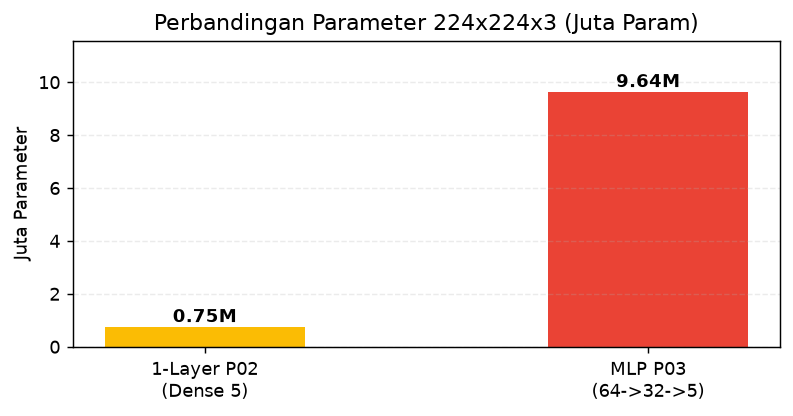

In [6]:
# TODO 1: Lengkapi Hidden Layer 1 (64 neuron) & Hidden Layer 2 (32 neuron) dengan aktivasi "relu"
hidden_1 = None  # TODO 1A
hidden_2 = None  # TODO 1B

model_mlp = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    tf.keras.layers.Flatten(),
    hidden_1,
    hidden_2,
    tf.keras.layers.Dense(len(CLASS_NAMES), activation="softmax"),
], name="1_MLP")

assert model_mlp.count_params() == 9636101, "Cek lagi Dense(64, activation='relu') dan Dense(32, activation='relu')!"
print(f"Total parameter MLP (224x224x3): {model_mlp.count_params():,}")
tampilkan_ledakan_mlp(model_mlp)

<details>
<summary><b>💡 Hint &amp; Jawaban Tugas 1</b> (klik untuk membuka)</summary>

```python
hidden_1 = tf.keras.layers.Dense(64, activation="relu")
hidden_2 = tf.keras.layers.Dense(32, activation="relu")
```
</details>

---
## Langkah 2 (6 menit): Operasi Konvolusi 2D (`3×3`) & `MaxPooling` Nyata *(Sesuai Slide 11–13 & 37)*
Mari uji filter `Conv2D 3×3` dan `MaxPooling2D(2)` langsung ke foto Elsa `32×32` agar terlihat **Feature Map** tepinya!

### Tugas 2 (`# TODO 2`): Buat Layer `Conv2D` & `MaxPooling2D`
Lengkapi `Conv2D(1, kernel_size=3, use_bias=False)` dan `MaxPooling2D(pool_size=(2, 2))`.

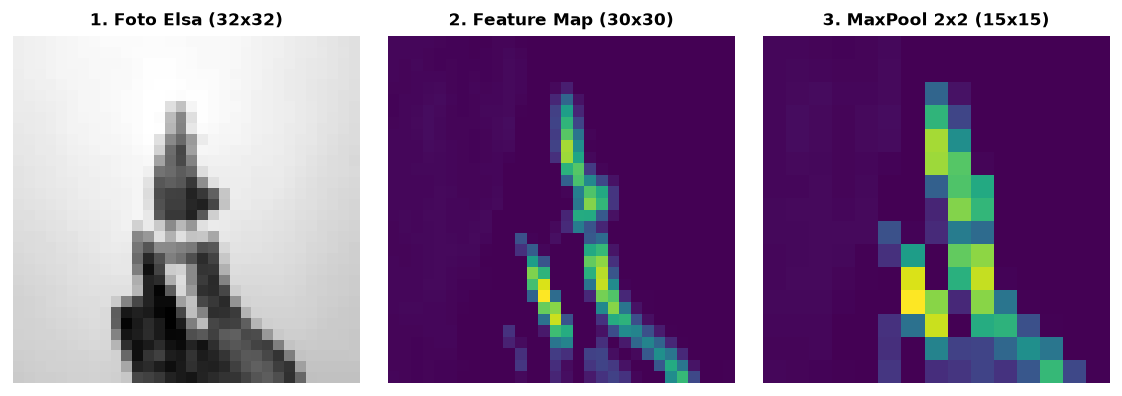

Ukuran menyusut rapi: (32,32) -> Feature Map (30, 30) -> Pool (15, 15) ✅


In [7]:
# TODO 2: Lengkapi layer konvolusi 3x3 & pooling 2x2
conv_layer = None  # TODO 2A
pool_layer = None  # TODO 2B

fmap, pooled = tampilkan_conv_pool_elsa(elsa_32, conv_layer, pool_layer)
assert fmap.shape == (1, 30, 30, 1) and pooled.shape == (1, 15, 15, 1)
print(f"Ukuran menyusut rapi: (32,32) -> Feature Map {tuple(fmap.shape[1:3])} -> Pool {tuple(pooled.shape[1:3])} ✅")

<details>
<summary><b>💡 Hint &amp; Jawaban Tugas 2</b> (klik untuk membuka)</summary>

```python
conv_layer = tf.keras.layers.Conv2D(1, kernel_size=3, use_bias=False)
pool_layer = tf.keras.layers.MaxPooling2D(pool_size=(2, 2))
```
</details>

---
## Langkah 3 (6 menit): Arsitektur #2 — Merakit **CNN Klasik** + `GAP` vs MLP *(Sesuai Slide 11–14 & 38)*
Dengan 3 blok konvolusi + `GlobalAveragePooling2D()` (pengganti `Flatten`), jumlah parameter pada `224×224×3` anjlok drastis dari `9.64M` menjadi **`101.829`**!

### Tugas 3 (`# TODO 3`): Lengkapi `MaxPooling2D` & `GlobalAveragePooling2D` pada CNN Klasik
Isi bagian `# TODO 3A` dengan `MaxPooling2D(2)` dan `# TODO 3B` dengan `GlobalAveragePooling2D()`.

In [8]:
# TODO 3: Lengkapi MaxPooling2D(2) & GlobalAveragePooling2D() pada CNN Klasik
pool_1 = None    # TODO 3A
gap_head = None  # TODO 3B

model_cnn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
    pool_1,
    tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(2),
    tf.keras.layers.Conv2D(128, 3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(2),
    gap_head,
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(len(CLASS_NAMES), activation="softmax"),
], name="2_CNN_Klasik")

assert model_cnn.count_params() == 101829, f"Expected 101829, got {model_cnn.count_params()}"
print(f"Parameter CNN Klasik: {model_cnn.count_params():,} (~95x lebih hemat dari MLP!) ✅")

Parameter CNN Klasik: 101,829 (~95x lebih hemat dari MLP!) ✅


<details>
<summary><b>💡 Hint &amp; Jawaban Tugas 3</b> (klik untuk membuka)</summary>

```python
pool_1 = tf.keras.layers.MaxPooling2D(2)
gap_head = tf.keras.layers.GlobalAveragePooling2D()
```
</details>

### Uji Belajar Nyata: MLP vs CNN Klasik pada Foto Frozen (`48×48`)
Jalankan sel di bawah untuk melihat bagaimana **CNN Klasik** jauh lebih progresif belajar daripada **MLP**.

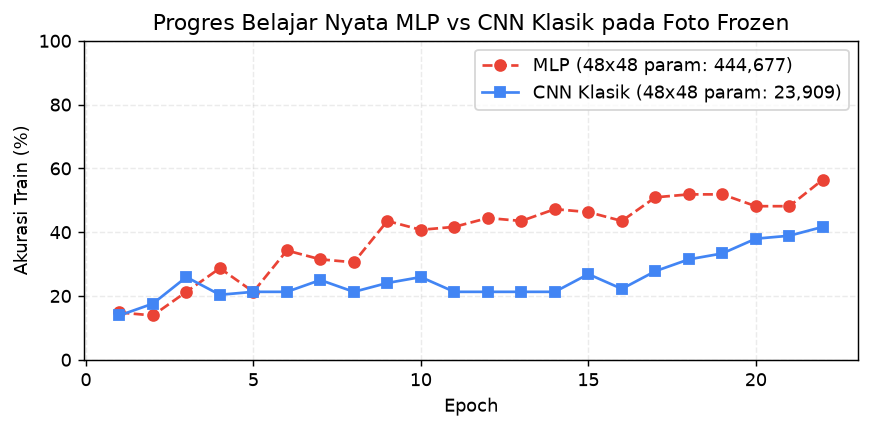

In [9]:
EPOCHS_UJI = 3 if SMOKE_TEST else 22
bandingkan_training_mlp_vs_cnn(X_48, y_48, epochs=EPOCHS_UJI, seed=SEED)

---
## Langkah 4 (7 menit): Arsitektur #3 — **Skip Connection (`Add()`)** & Inspeksi `ResNet50` *(Sesuai Slide 17–20 & 39)*
Model bercabang seperti **ResNet** (`y = F(x) + x`) tidak bisa ditulis dengan `Sequential`, melainkan memakai **Keras Functional API**. Mari rakit blok pintasnya lalu muat `ResNet50(weights=None)`!

### Tugas 4 (`# TODO 4`): Sambungkan `Add()([fx, shortcut])` & Muat `ResNet50`
Gunakan `tf.keras.layers.Add()([fx, shortcut])` untuk menyambungkan jalan pintas, lalu muat `ResNet50(include_top=False, weights=None, input_shape=(IMG_SIZE, IMG_SIZE, 3))`.

In [10]:
# Buat contoh blok ResNet mini dengan Functional API
inp_mini = tf.keras.Input(shape=(28, 28, 16))
shortcut = inp_mini
fx = tf.keras.layers.Conv2D(16, 3, padding="same", activation="relu")(inp_mini)
fx = tf.keras.layers.Conv2D(16, 3, padding="same")(fx)

# TODO 4A: Jumlahkan fx dan shortcut memakai tf.keras.layers.Add()
out_skip = None  # TODO 4A
mini_res_block = tf.keras.Model(inp_mini, tf.keras.layers.ReLU()(out_skip))

# TODO 4B: Muat arsitektur penuh ResNet50 tanpa bobot (offline-safe)
res_base = None  # TODO 4B

n_skip_res50 = sum(isinstance(l, tf.keras.layers.Add) for l in res_base.layers)
assert n_skip_res50 == 16, f"Seharusnya ada 16 layer Add() di ResNet50, ketemu {n_skip_res50}"
print(f"ResNet50 berhasil dimuat! Total layer: {len(res_base.layers)} | Jumlah Skip Add(): {n_skip_res50} ✅")

ResNet50 berhasil dimuat! Total layer: 175 | Jumlah Skip Add(): 16 ✅


<details>
<summary><b>💡 Hint &amp; Jawaban Tugas 4</b> (klik untuk membuka)</summary>

```python
out_skip = tf.keras.layers.Add()([fx, shortcut])
res_base = tf.keras.applications.ResNet50(include_top=False, weights=None, input_shape=(IMG_SIZE, IMG_SIZE, 3))
```
</details>

---
## Langkah 5 (8 menit): Arsitektur #4 & #5 — Membedah **MobileNetV2** & **EfficientNetB0** *(Sesuai Slide 23–30 & 40)*
Sekarang mari buktikan sendiri dua ciri pembeda utama dua arsitektur efisien modern di Keras:
1. **`MobileNetV2`:** memiliki `17` layer **`DepthwiseConv2D`** (*Depthwise Separable Convolution*) + `10` Skip `Add()`.
2. **`EfficientNetB0`:** mewarisi blok Depthwise (`16`) sekaligus menambahkan **`16` gerbang *SE Attention* (`Multiply`)**!

### Tugas 5 (`# TODO 5`): Muat `MobileNetV2` & Hitung `DepthwiseConv2D`
Muat `tf.keras.applications.MobileNetV2(include_top=False, weights=None, input_shape=(IMG_SIZE, IMG_SIZE, 3))`.

In [11]:
# TODO 5: Muat MobileNetV2 tanpa head & weights=None
mob_base = None  # TODO 5

n_dw = sum(isinstance(l, tf.keras.layers.DepthwiseConv2D) for l in mob_base.layers)
assert n_dw == 17, f"Expected 17 DepthwiseConv2D, got {n_dw}"
print(f"MobileNetV2 backbone: {mob_base.count_params():,} param | DepthwiseConv2D: {n_dw} layer ✅")

MobileNetV2 backbone: 2,257,984 param | DepthwiseConv2D: 17 layer ✅


<details>
<summary><b>💡 Hint &amp; Jawaban Tugas 5</b> (klik untuk membuka)</summary>

```python
mob_base = tf.keras.applications.MobileNetV2(include_top=False, weights=None, input_shape=(IMG_SIZE, IMG_SIZE, 3))
```
</details>

### Tugas 6 (`# TODO 6`): Muat `EfficientNetB0` & Hitung Gerbang SE (`Multiply`)
Muat `tf.keras.applications.EfficientNetB0(include_top=False, weights=None, input_shape=(IMG_SIZE, IMG_SIZE, 3))`.

In [12]:
# TODO 6: Muat EfficientNetB0 tanpa head & weights=None
eff_base = None  # TODO 6

n_se = sum(isinstance(l, tf.keras.layers.Multiply) for l in eff_base.layers)
assert n_se == 16, f"Expected 16 SE Multiply layers, got {n_se}"
print(f"EfficientNetB0 backbone: {eff_base.count_params():,} param | Gerbang SE Multiply: {n_se} layer ✅")

EfficientNetB0 backbone: 4,049,571 param | Gerbang SE Multiply: 16 layer ✅


<details>
<summary><b>💡 Hint &amp; Jawaban Tugas 6</b> (klik untuk membuka)</summary>

```python
eff_base = tf.keras.applications.EfficientNetB0(include_top=False, weights=None, input_shape=(IMG_SIZE, IMG_SIZE, 3))
```
</details>

---
## Langkah 6 (7 menit): Benchmark 5 Arsitektur & Simpan ke `results/` *(Sesuai Slide 31 & 41)*
Mari pasang kepala klasifikasi 5 kelas (`GAP → Dense(5, softmax)`) di atas `ResNet50`, `MobileNetV2`, dan `EfficientNetB0`, lalu jalankan helper pengukur inferensi nyata pada 8 foto Frozen!

In [13]:
# Rangkai kepala 5 kelas Frozen pada ResNet50, MobileNetV2, & EfficientNetB0
def pasang_head_5kelas(base_model, nama):
    inp = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = base_model(inp, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    out = tf.keras.layers.Dense(len(CLASS_NAMES), activation="softmax")(x)
    return tf.keras.Model(inp, out, name=nama)

model_res50 = pasang_head_5kelas(res_base, "3_ResNet50")
model_mobv2 = pasang_head_5kelas(mob_base, "4_MobileNetV2")
model_effb0 = pasang_head_5kelas(eff_base, "5_EfficientNetB0")

daftar_5_model = {
    "1. MLP": (model_mlp, model_mlp),
    "2. CNN Klasik": (model_cnn, model_cnn),
    "3. ResNet50": (model_res50, res_base),
    "4. MobileNetV2": (model_mobv2, mob_base),
    "5. EfficientNetB0": (model_effb0, eff_base),
}
print("✅ Ke-5 arsitektur lengkap siap dibenchmark!")

✅ Ke-5 arsitektur lengkap siap dibenchmark!


### Tugas 7 (`# TODO 7`): Jalankan Benchmark Nyata 5 Arsitektur
Panggil `kumpulkan_benchmark_5_arsitektur(daftar_5_model, batch_frozen_8)` lalu cetak tabel hasilnya.

In [14]:
# TODO 7: Ukur parameter, ukuran MB, & latensi batch 8 foto Frozen untuk 5 arsitektur
df_bench = None  # TODO 7

assert df_bench is not None and len(df_bench) == 5, "df_bench harus berisi tepat 5 baris arsitektur!"
df_bench

,arsitektur,total_params,est_size_mb,latensi_ms,jumlah_layer_base
0,1. MLP,9636101,36.76,20.9,4
1,2. CNN Klasik,101829,0.39,151.8,9
2,3. ResNet50,23597957,90.02,1579.4,175
3,4. MobileNetV2,2264389,8.64,722.7,154
4,5. EfficientNetB0,4055976,15.47,1260.1,237


<details>
<summary><b>💡 Hint &amp; Jawaban Tugas 7</b> (klik untuk membuka)</summary>

```python
df_bench = kumpulkan_benchmark_5_arsitektur(daftar_5_model, batch_frozen_8)
```
</details>

### Tugas 8 (`# TODO 8`): Ekspor Tabel CSV & Grafik Kuadran ke `results/`
Simpan `df_bench` ke `RESULTS_DIR / 'p03_5_architectures_benchmark.csv'` dan tampilkan grafik kuadrannya.

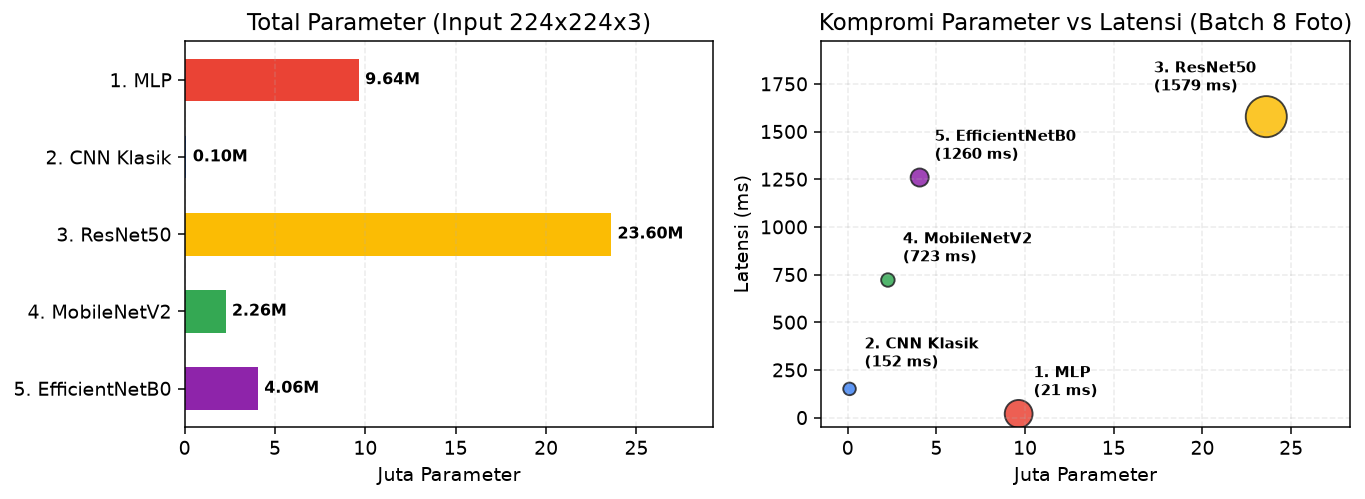

✅ Tersimpan rapi: p03_5_architectures_benchmark.csv & p03_5_architectures_benchmark.png


In [15]:
out_csv = RESULTS_DIR / "p03_5_architectures_benchmark.csv"
out_png = RESULTS_DIR / "p03_5_architectures_benchmark.png"

# TODO 8: Simpan df_bench ke out_csv (index=False) lalu panggil plot_kuadran_5_arsitektur(df_bench, simpan_ke=out_png)
# TODO 8

assert out_csv.exists() and out_png.exists(), "Pastikan out_csv dan out_png sudah tersimpan!"
print(f"✅ Tersimpan rapi: {out_csv.name} & {out_png.name}")

<details>
<summary><b>💡 Hint &amp; Jawaban Tugas 8</b> (klik untuk membuka)</summary>

```python
df_bench.to_csv(out_csv, index=False)
plot_kuadran_5_arsitektur(df_bench, simpan_ke=out_png)
```
</details>

---
## Ringkasan & Mini-Challenge *(Selaras Slide 42 & 49–50)*
- Dari eksperimen nyata barusan:
  1. **MLP** (`9.64M` param) boros bobot karena `Flatten`.
  2. **CNN Klasik** (`101.8K` param) memangkas parameter ~95× lewat *Parameter Sharing & Pooling*.
  3. **ResNet50** (`23.60M` param / `90.0 MB`) memakai `16` blok *Skip Connection* (`Add()`), akurat tapi berat.
  4. **MobileNetV2** (`2.26M` param / `8.64 MB`) memakai `17` `DepthwiseConv2D` & cepat dieksekusi → **kandidat #1 proyek Frozen!**
  5. **EfficientNetB0** (`4.06M` param / `15.5 MB`) menambah `16` gerbang *SE Attention* (`Multiply`) untuk fokus kanal penting.
- **Persiapan P04:** Di **P04 — Arsitektur CNN & Transfer Learning**, kita akan menyalakan bobot *pretrained ImageNet* pada **MobileNetV2** agar akurasi di 143 foto Frozen melonjak tinggi!

### Referensi Materi *(Selaras Slide 51–52 · `docs/PLAN.md`)*
1. [3Blue1Brown — *But what is a Neural Network?*](https://www.youtube.com/watch?v=aircAruvnKk)
2. [Coursera (DeepLearning.AI) — *Foundations of CNN Week 1*](https://www.coursera.org/learn/convolutional-neural-networks)
3. [CNN Explainer](https://poloclub.github.io/cnn-explainer/) `[CEK LINK]`
4. [Stanford CS231n — *Convolutional Networks*](https://cs231n.github.io/convolutional-networks/) `[CEK LINK]`
5. [Dumoulin & Visin — *A Guide to Convolution Arithmetic*](https://arxiv.org/abs/1603.07285) `[CEK LINK]`
6. [He dkk. — *Deep Residual Learning (ResNet)*](https://arxiv.org/abs/1512.03385) `[CEK LINK]`
7. [Sandler dkk. — *MobileNetV2: Inverted Residuals*](https://arxiv.org/abs/1801.04381)
8. [Tutorial TensorFlow — *Transfer Learning & Fine-tuning (ID)*](https://www.tensorflow.org/tutorials/images/transfer_learning?hl=id)
9. [Roboflow — *How to Train MobileNetV2 on a Custom Dataset*](https://roboflow.com/blog/how-to-train-mobilenetv2-on-a-custom-dataset)
10. [Keras Guides — *Functional API & Applications*](https://keras.io/guides/) `[CEK LINK]`